# 03 (v2) - Graph-constrained synthetic defects with consequence labels
Runtime: **CPU**. Run after 02 v2.

Defects are chosen on the connectivity graph of a defect-free template (connected components of copper = nets, skeleton = conductor path). The **consequence label** (`open` / `short`) comes from recomputed connectivity, not appearance.

Fixes vs v1: no train/test prefix hack; synthetic set is generated for **all** boards and tagged with `source_board`, so notebook 04 picks only the train boards of whichever split/fold it uses (no leakage); breaks that do not disconnect the net (`width_loss`) are **dropped**, not labelled `open`; RNG is seeded per image/op, so results do not depend on cell run order.

Nets are raster components of the template, not a netlist. Gerber-derived nets would be the stronger version.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys, os
D = '/content/drive/MyDrive/pcbrisk'
sys.path.insert(0, f'{D}/code')
from pcbrisk_utils import *
seed_all(42)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
sh('pip -q install scikit-image opencv-python-headless scipy pandas pyyaml')
import numpy as np, cv2, json, shutil, pandas as pd
from scipy import ndimage as ndi
from skimage.morphology import skeletonize, remove_small_objects
from pathlib import Path
from IPython.display import Image

if not os.path.exists(f'{L}/raw/DeepPCB'):
    sh(f'unzip -q {D}/00_raw/deeppcb_main.zip -d {L}/raw')
man = pd.read_csv(f'{D}/01_prepared/split_manifest_v2.csv', dtype={'image_id': str})
board_of = dict(zip(man.image_id, man.source_board))
P = Path(f'{L}/raw/DeepPCB/PCBData')
temps = [p for p in sorted(P.glob('group*/*/*_temp.jpg')) if p.name.replace('_temp.jpg','') in board_of]
print(len(temps), 'templates matched to manifest (expect 1500)')

1500 templates matched to manifest (expect 1500)


copper fraction 0.14 components 7


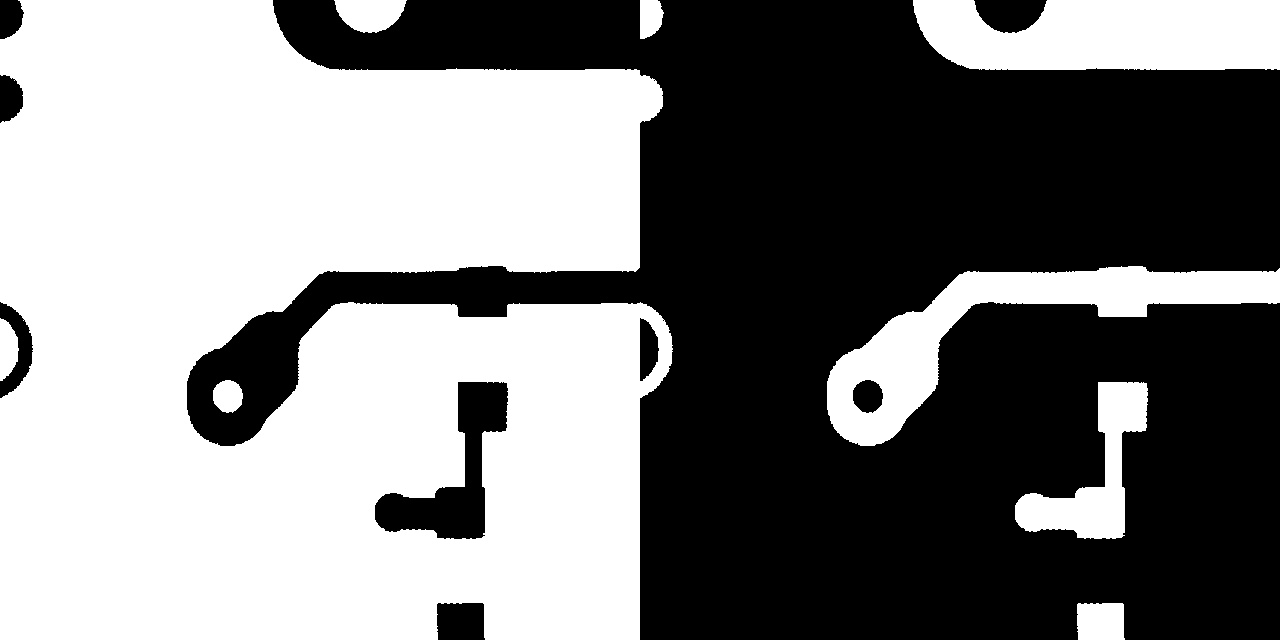

In [ ]:
def copper_mask(img, copper='auto'):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, t = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = t > 0
    if copper == 'dark' or (copper == 'auto' and m.mean() > 0.5):
        m = ~m                      # copper assumed to be the minority class
    return remove_small_objects(m, 30)

img = cv2.imread(str(temps[0])); m = copper_mask(img)
lab, n = ndi.label(m, structure=np.ones((3,3)))
print('copper fraction', m.mean().round(3), 'components', n)
cv2.imwrite('/content/preview_mask.png', np.hstack([img, cv2.cvtColor((m*255).astype(np.uint8), cv2.COLOR_GRAY2BGR)]))
Image('/content/preview_mask.png')
# CHECK: right panel must show traces WHITE. If inverted set COPPER below to 'dark' or 'light'.

In [ ]:
COPPER = 'auto'      # 'dark' | 'light' | 'auto'   <- fix after looking at the preview
MIN_AREA = 200

def n_pieces(mask, region):
    lab, n = ndi.label(mask & region, structure=np.ones((3,3)))
    if n == 0: return 0
    areas = ndi.sum(np.ones_like(lab), lab, index=range(1, n+1))
    return int((areas >= 30).sum())

def op_break(img, m, lab, n, rng):
    comps = [i for i in range(1, n+1) if (lab == i).sum() >= MIN_AREA]
    if not comps: return None
    c = int(rng.choice(comps)); region = lab == c
    ys, xs = np.nonzero(skeletonize(region))
    if len(ys) == 0: return None
    j = int(rng.integers(len(ys))); y, x = ys[j], xs[j]
    dist = ndi.distance_transform_edt(region)
    r = int(dist[y, x]) + int(rng.integers(2, 5))
    cut = np.zeros(m.shape, np.uint8); cv2.circle(cut, (int(x), int(y)), r, 1, -1)
    cut = cut.astype(bool) & region
    m2 = m & ~cut
    before, after = n_pieces(m, region), n_pieces(m2, region)
    cons = 'open' if after > before else 'width_loss'
    img2 = img.copy(); img2[cut] = np.median(img[~m], axis=0)
    ys2, xs2 = np.nonzero(cut)
    return img2, (xs2.min(), ys2.min(), xs2.max(), ys2.max()), dict(op='break', consequence=cons, net=c, width_px=float(2*dist[y, x]), pieces_before=before, pieces_after=after), 0

def op_bridge(img, m, lab, n, rng, max_gap=14):
    comps = [i for i in range(1, n+1) if (lab == i).sum() >= MIN_AREA]
    if len(comps) < 2: return None
    a = int(rng.choice(comps)); A = lab == a
    dist, (iy, ix) = ndi.distance_transform_edt(~A, return_indices=True)
    cand = np.isin(lab, comps) & (lab != a) & (dist <= max_gap) & (dist >= 3)
    ys, xs = np.nonzero(cand)
    if len(ys) == 0: return None
    j = int(rng.integers(len(ys))); yb, xb = ys[j], xs[j]
    ya, xa = iy[yb, xb], ix[yb, xb]
    t = int(rng.integers(3, 7))
    br = np.zeros(m.shape, np.uint8); cv2.line(br, (int(xa), int(ya)), (int(xb), int(yb)), 1, t); br = br.astype(bool)
    lab2, _ = ndi.label(m | br, structure=np.ones((3,3)))
    merged = bool(lab2[ya, xa] == lab2[yb, xb] and lab[ya, xa] != lab[yb, xb])
    new = br & ~m
    if not new.any(): return None
    img2 = img.copy(); img2[new] = np.median(img[m], axis=0)
    ys2, xs2 = np.nonzero(new)
    return img2, (xs2.min(), ys2.min(), xs2.max(), ys2.max()), dict(op='bridge', consequence='short' if merged else 'none', net=a, net_b=int(lab[yb, xb]), gap_px=float(dist[yb, xb]), width_px=t), 1

OPS = [op_break, op_bridge]
KEEP = {'break': 'open', 'bridge': 'short'}     # only verified graph changes become detector labels

In [ ]:
N_PER_OP = 1         # variants per template per op (1,500 templates -> ~3,000 samples)
MAX_TRIES = 8
OUT = Path(f'{L}/data/synth'); shutil.rmtree(OUT, ignore_errors=True)
(OUT/'images').mkdir(parents=True); (OUT/'labels').mkdir(parents=True)
meta, dropped = [], {'break': 0, 'bridge': 0}
for p in temps:
    stem = p.name.replace('_temp.jpg', '')
    img = cv2.imread(str(p)); m = copper_mask(img, COPPER)
    lab, n = ndi.label(m, structure=np.ones((3,3)))
    for oi, op in enumerate(OPS):
        for k in range(N_PER_OP):
            rng = np.random.default_rng([int(stem), oi, k])       # per-sample seed: order-independent
            res = None
            for t in range(MAX_TRIES):
                r = op(img, m, lab, n, rng)
                if r and r[2]['consequence'] == KEEP[r[2]['op']]:
                    res = (r, t + 1); break
            name = 'break' if oi == 0 else 'bridge'
            if res is None:
                dropped[name] += 1; continue
            (img2, (x1, y1, x2, y2), info, cls), tries = res
            pad = 4; x1, y1, x2, y2 = max(0, x1-pad), max(0, y1-pad), min(639, x2+pad), min(639, y2+pad)
            sid = f'syn_{stem}_{info["op"]}{k}'
            cv2.imwrite(str(OUT/'images'/f'{sid}.jpg'), img2)
            open(OUT/'labels'/f'{sid}.txt', 'w').write(f'{cls} {(x1+x2)/2/640:.6f} {(y1+y2)/2/640:.6f} {(x2-x1)/640:.6f} {(y2-y1)/640:.6f}')
            meta.append(dict(synth_id=sid, template=stem, source_board=board_of[stem], bbox=[int(x1),int(y1),int(x2),int(y2)], tries=tries, **info))
mdf = pd.DataFrame(meta); mdf.to_csv(OUT/'synth_meta.csv', index=False)
print(len(mdf), 'samples kept; templates where no valid defect was found:', dropped)
print(mdf.groupby(['op', 'consequence']).size())

2225 samples kept; templates where no valid defect was found: {'break': 15, 'bridge': 760}
op      consequence
break   open           1485
bridge  short           740
dtype: int64


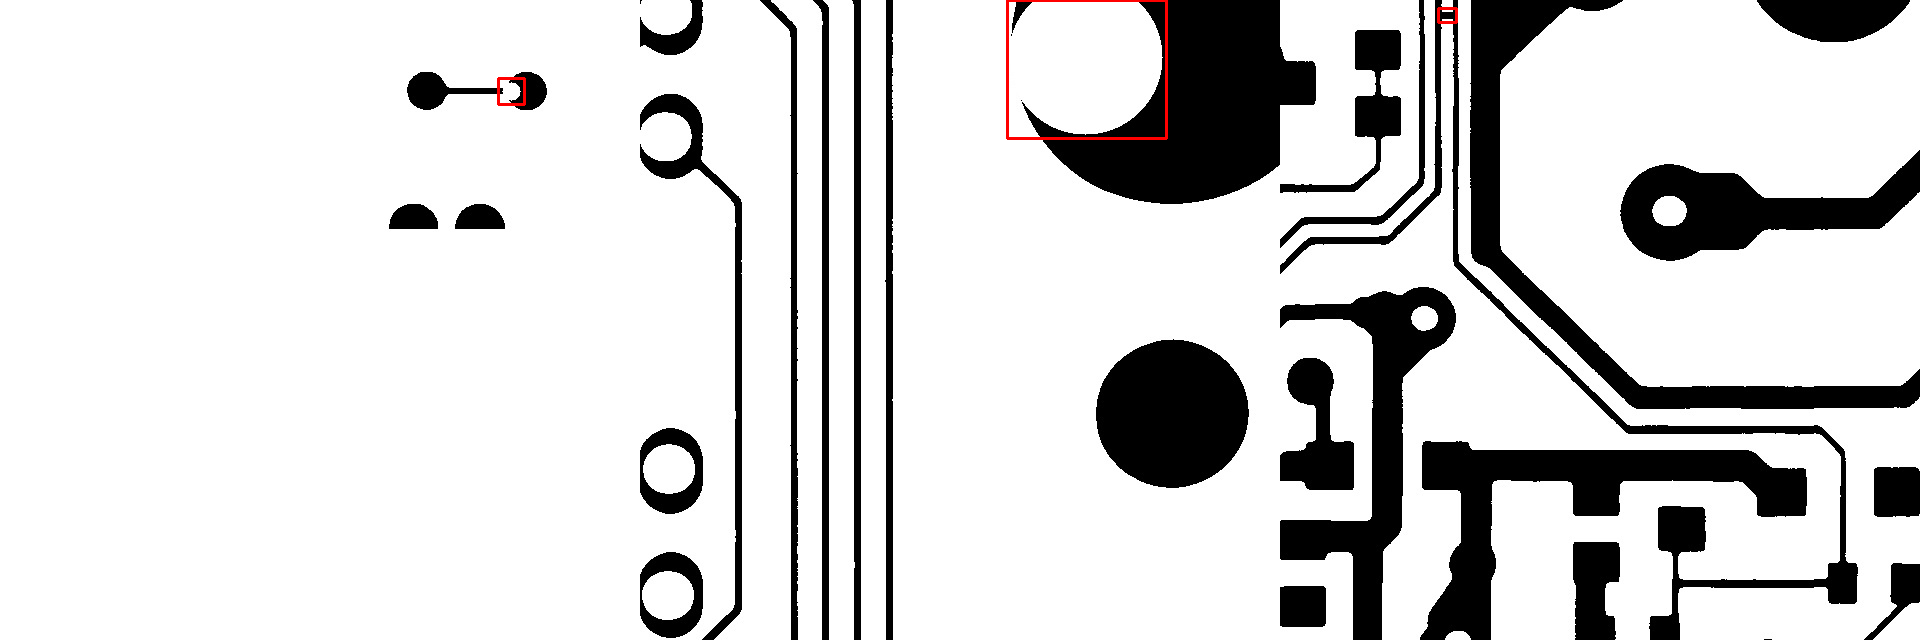

In [ ]:
tiles = []
for _, row in mdf.sample(3, random_state=1).iterrows():
    im = cv2.imread(str(OUT/'images'/f'{row.synth_id}.jpg')); x1, y1, x2, y2 = row.bbox
    cv2.rectangle(im, (x1, y1), (x2, y2), (0, 0, 255), 2); tiles.append(im)
cv2.imwrite('/content/synth_preview.png', np.hstack(tiles)); Image('/content/synth_preview.png')

In [ ]:
cfg = dict(version='synth_v2', copper=COPPER, min_area=MIN_AREA, n_per_op=N_PER_OP, max_tries=MAX_TRIES,
           ops=[o.__name__ for o in OPS], per_sample_seed='[int(stem), op_idx, k]',
           manifest=open(f'{D}/01_prepared/manifest_v2.sha256').read())
if os.path.exists(f'{D}/02_synth/synth_v2.tar'):
    print('synth_v2 exists - immutable. Use v3.')
else:
    open(f'{D}/02_synth/synth_v2_config.json', 'w').write(json.dumps(cfg, indent=1))
    sh(f'cd {L}/data && tar -cf {L}/synth_v2.tar synth')
    safe_copy(f'{L}/synth_v2.tar', f'{D}/02_synth/synth_v2.tar')
    safe_copy(f'{OUT}/synth_meta.csv', f'{D}/02_synth/synth_meta_v2.csv')
    print('saved')

saved
